# 2 · Build a dataset

Start with ten labels from notebook 0. Find a Sentinel-2 image for each label's place and day, then save the pairs:

```text
data/my_dataset/
├── train/  sentinel-2-l2a/<tile>.tif  label/<tile>.tif
├── val/    ...
├── test/   ...
└── catalog.parquet
```

We will also save six forest scenes for prediction in notebook 3. This notebook needs internet access.


In [9]:
from pathlib import Path

from dask.diagnostics.progress import ProgressBar
from huggingface_hub import snapshot_download

import geosave as gs

# Show progress when reading pixels.
pbar = ProgressBar(minimum=1)
pbar.register()

root = Path(
    snapshot_download(
        "fatmur/dynamicworld-300", repo_type="dataset", local_dir="data/dynamic_world"
    )
)

Fetching 603 files:   0%|          | 0/603 [00:00<?, ?it/s]

## Read a label's place and date

Its `anchor` holds the grid and date needed to search for an image.


In [10]:
label_path = sorted((root / "train/labels").glob("*.tif"))[0]
label = gs.open_raster(label_path)

anchor = label.gs.anchor
anchor.format(
    "{lat:.2f}, {lon:.2f} · {start:%Y-%m-%d} · {width:g} m across at {res:g} m"
)

'20.13, -100.22 · 2019-01-30 · 5100 m across at 10 m'

:Overlay
   .RGB.I                     :RGB   [x,y]   (R,G,B)
   .Points.Water              :Points   [x,y]
   .Points.Trees              :Points   [x,y]
   .Points.Grass              :Points   [x,y]
   .Points.Flooded_vegetation :Points   [x,y]
   .Points.Crops              :Points   [x,y]
   .Points.Scrub              :Points   [x,y]
   .Points.Built_area         :Points   [x,y]
   .Points.Bare_ground        :Points   [x,y]
   .Points.Snow_ice           :Points   [x,y]
   .Points.Cloud              :Points   [x,y]
   .Points.Unlabelled         :Points   [x,y]
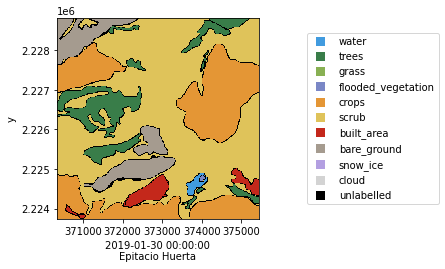

In [11]:
label.gs.plot()

## Find the image

A [STAC](https://stacspec.org) catalog lists scenes by place and date.

Choose four Sentinel-2 bands. If several scenes match, keep the least cloudy one. Search the label's own day so the image matches the label.


In [12]:
bands = ["B02", "B03", "B04", "B08"]

client = gs.StacClient.open("planetary_computer")
source = client.source("sentinel-2-l2a")
source = source.set_config(bands=bands, dtype="uint16", nodata=0)
source = source.set_query(sortby=["properties.eo:cloud_cover"], max_items=1)

Search the full day without loading pixels.


In [13]:
day = anchor.replace(timespan=anchor.format("{start:%Y-%m-%d}"))
source.search(day)

,assets,collection,geometry,id,links,stac_extensions,stac_version,type,constellation,datetime,...,s2:product_uri,s2:reflectance_conversion_factor,s2:saturated_defective_pixel_percentage,s2:snow_ice_percentage,s2:thin_cirrus_percentage,s2:unclassified_percentage,s2:vegetation_percentage,s2:water_percentage,sat:orbit_state,sat:relative_orbit
0,"{'AOT': {'gsd': 10, 'href': 'https://sentinel2...",sentinel-2-l2a,"POLYGON ((-99.86545 20.5702, -99.89441 20.4547...",S2A_MSIL2A_20190130T171541_R112_T14QLH_2020100...,[{'href': 'https://planetarycomputer.microsoft...,[https://stac-extensions.github.io/eo/v1.1.0/s...,1.1.0,Feature,Sentinel 2,2019-01-30 17:15:41.024000+00:00,...,S2A_MSIL2A_20190130T171541_N0212_R112_T14QLH_2...,1.031508,0.0,0.0,0.0,0.672362,16.4481,1.649036,descending,112


Load the image on the label's grid. Record its reflectance scale and RGB bands. Plotting reads the pixels.


[########################################] | 100% Completed | 1.30 s
[########################################] | 100% Completed | 1.31 s
[########################################] | 100% Completed | 1.21 s
[########################################] | 100% Completed | 1.31 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.20 s
[########################################] | 100% Completed | 1.30 s
[########################################] | 100% Completed | 1.41 s


:Layout
   .RGB.I     :RGB   [x,y]   (R,G,B)
   .Overlay.I :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Scrub              :Points   [x,y]
      .Points.Built_area         :Points   [x,y]
      .Points.Bare_ground        :Points   [x,y]
      .Points.Snow_ice           :Points   [x,y]
      .Points.Cloud              :Points   [x,y]
      .Points.Unlabelled         :Points   [x,y]
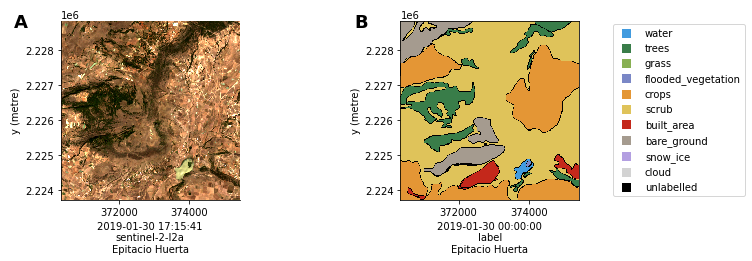

In [14]:
image = source.load(day)
image = image.gs.write_packing(1e-4)
image = image.gs.write_rgb(red="B04", green="B03", blue="B02")

pair = gs.tree({"sentinel-2-l2a": image, "label": label})
pair.gs.plot(cols=2)

## Save the pair

Write the image and label as Cloud-Optimized GeoTIFFs. `{collection}` gives each its own folder; both use the label's filename.


In [15]:
folder = Path("data/my_dataset")

scenes = pair.gs.to_cog(
    folder / "train" / "{collection}" / f"{label_path.stem}.tif", overwrite=True
)
scenes

[########################################] | 100% Completed | 1.21 s
[########################################] | 100% Completed | 1.31 s
[########################################] | 100% Completed | 1.20 s
[########################################] | 100% Completed | 1.30 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.21 s
[########################################] | 100% Completed | 1.21 s


[Scene('sentinel-2-l2a', {'image': dw_-100.2161543359_20.1295348778-20190130.tif}),
 Scene('label', {'label': dw_-100.2161543359_20.1295348778-20190130.tif})]

## Catalog the files

Create STAC Items from the saved files, then put them in a GeoDataFrame. Add `split` as an ordinary column.

A catalog stores file paths and metadata, not pixels.


In [16]:
label_collection = gs.stac.create_collection(
    "label", description="Dynamic World reference labels"
)
collections = [source.collection, label_collection]
items = gs.stac.create_catalog(
    gs.stac.create_items(scenes, id_format=label_path.stem), collections=collections
)
items["split"] = "train"
items

,assets,collection,geometry,id,links,stac_extensions,stac_version,type,datetime,split
0,{'image': {'eo:bands': [{'center_wavelength': ...,sentinel-2-l2a,"POLYGON ((-100.24064 20.1524, -100.24064 20.15...",dw_-100.2161543359_20.1295348778-20190130,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 17:15:41.024000+00:00,train
1,"{'image': None, 'label': {'eo:bands': [{'name'...",label,"POLYGON ((-100.24064 20.1524, -100.24064 20.15...",dw_-100.2161543359_20.1295348778-20190130,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 00:00:00+00:00,train


## Build all three splits

`fetch_image` loads an image. `save_tile` saves an image/label pair. `build_dataset` repeats those steps and returns a catalog for one split.


In [17]:
from tqdm.auto import tqdm


def fetch_image(anchor):
    image = source.load(anchor)
    image = image.gs.write_packing(1e-4)
    return image.gs.write_rgb(red="B04", green="B03", blue="B02")


def save_tile(label_path, folder):
    label = gs.open_raster(label_path)
    anchor = label.gs.anchor
    day = anchor.replace(timespan=anchor.format("{start:%Y-%m-%d}"))
    pair = gs.tree({"sentinel-2-l2a": fetch_image(day), "label": label})
    return pair.gs.to_cog(
        folder / "{collection}" / f"{label_path.stem}.tif", overwrite=True
    )


def build_dataset(labels, folder, split):
    items = []
    for path in tqdm(labels, desc=split):
        scenes = save_tile(path, folder / split)
        items.extend(gs.stac.create_items(scenes, id_format=path.stem))
    catalog = gs.stac.create_catalog(items, collections=collections)
    catalog["split"] = split
    return catalog

Use six training labels, two validation labels and two test labels for this short example.


In [18]:
pbar.unregister()

train_labels = sorted((root / "train/labels").glob("*.tif"))[:1]
val_labels = sorted((root / "val/labels").glob("*.tif"))[:1]
test_labels = sorted((root / "test/labels").glob("*.tif"))[:1]

train = build_dataset(train_labels, folder, "train")
val = build_dataset(val_labels, folder, "val")
test = build_dataset(test_labels, folder, "test")

catalog = gs.GeoCatalog.concat([train, val, test])
catalog.gs.to_geoparquet(folder / "catalog.parquet", overwrite=True)
catalog

train:   0%|          | 0/1 [00:00<?, ?it/s]

[########################################] | 100% Completed | 1.41 s
[########################################] | 100% Completed | 2.01 s
[########################################] | 100% Completed | 1.61 s
[########################################] | 100% Completed | 1.21 s


val:   0%|          | 0/1 [00:00<?, ?it/s]

[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.10 s


test:   0%|          | 0/1 [00:00<?, ?it/s]

[########################################] | 100% Completed | 1.81 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.10 s
[########################################] | 100% Completed | 1.10 s


,assets,collection,geometry,id,links,stac_extensions,stac_version,type,datetime,split
0,{'image': {'eo:bands': [{'center_wavelength': ...,sentinel-2-l2a,"POLYGON ((-100.24064 20.1524, -100.24064 20.15...",dw_-100.2161543359_20.1295348778-20190130,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 17:15:41.024000+00:00,train
1,"{'image': None, 'label': {'eo:bands': [{'name'...",label,"POLYGON ((-100.24064 20.1524, -100.24064 20.15...",dw_-100.2161543359_20.1295348778-20190130,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 00:00:00+00:00,train
2,{'image': {'eo:bands': [{'center_wavelength': ...,sentinel-2-l2a,"POLYGON ((-100.45467 19.84206, -100.45467 19.8...",dw_-100.4301567231_19.8192692735-20190130,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 17:15:41.024000+00:00,val
3,"{'image': None, 'label': {'eo:bands': [{'name'...",label,"POLYGON ((-100.45467 19.84206, -100.45467 19.8...",dw_-100.4301567231_19.8192692735-20190130,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 00:00:00+00:00,val
4,{'image': {'eo:bands': [{'center_wavelength': ...,sentinel-2-l2a,"POLYGON ((-100.39331 23.17848, -100.39331 23.1...",dw_-100.3682525093_23.1557486708-20181221,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2018-12-21 17:17:21.024000+00:00,test
5,"{'image': None, 'label': {'eo:bands': [{'name'...",label,"POLYGON ((-100.39331 23.17848, -100.39331 23.1...",dw_-100.3682525093_23.1557486708-20181221,[],[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2018-12-21 00:00:00+00:00,test


Open the catalog on a map. Select rows, then use **Open selected items** to view their rasters.


In [19]:
catalog.gs.explore().serve()

<StoppableThread(Thread-85 (get_server), started 139944805746368)>

## Reopen the catalog

The saved GeoParquet works as a STAC source. You can also export the catalog as STAC JSON.


In [20]:
catalog.gs.to_stac_json(folder / "stac", overwrite=True)

saved = gs.StacClient.open(folder / "catalog.parquet")
saved.search(gs.StacQuery(collections=["label"]))

Launching server at http://localhost:5006


,assets,collection,geometry,id,links,stac_extensions,stac_version,type,datetime,split
0,"{'label': {'eo:bands': [{'name': 'label'}], 'h...",label,"POLYGON ((-100.24064 20.1524, -100.24064 20.15...",dw_-100.2161543359_20.1295348778-20190130,"[{'href': './catalog.parquet', 'rel': 'collect...",[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 00:00:00+00:00,train
1,"{'label': {'eo:bands': [{'name': 'label'}], 'h...",label,"POLYGON ((-100.45467 19.84206, -100.45467 19.8...",dw_-100.4301567231_19.8192692735-20190130,"[{'href': './catalog.parquet', 'rel': 'collect...",[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2019-01-30 00:00:00+00:00,val
2,"{'label': {'eo:bands': [{'name': 'label'}], 'h...",label,"POLYGON ((-100.39331 23.17848, -100.39331 23.1...",dw_-100.3682525093_23.1557486708-20181221,"[{'href': './catalog.parquet', 'rel': 'collect...",[https://stac-extensions.github.io/projection/...,1.1.0,Feature,2018-12-21 00:00:00+00:00,test


## Start from a shape

Open the forest outline in `khdtk.geojson` and give it a 10 m grid. Fetch one scene from each month for prediction.


In [21]:
region = gs.open_vector("khdtk.geojson")
region_anchor = gs.GeoAnchor.from_geometry(region, resolution=10)

months = ["2019-05", "2019-06", "2019-07", "2019-08", "2019-09", "2019-10"]
pictures = []
for month in months:
    picture = fetch_image(region_anchor.replace(timespan=month))
    pictures.append(picture)

season = gs.transform.temporal.concat(pictures)
season

<xarray.Dataset> Size: 2MB
Dimensions:      (time: 6, y: 192, x: 168)
Coordinates:
  * time         (time) datetime64[ns] 48B 2019-05-19T02:35:51.024000 ... 201...
  * y            (y) float64 2kB 9.215e+06 9.215e+06 ... 9.213e+06 9.213e+06
  * x            (x) float64 1kB 4.368e+05 4.368e+05 ... 4.385e+05 4.385e+05
    spatial_ref  int32 4B 32749
Data variables:
    B02          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    B03          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    B04          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    B08          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
Attributes:
    id:           sentinel-2-l2a
    title:        Sentinel-2 Level-2A
    summary:      The [Sentinel-2](https://sentinel.esa.int/web/sentinel/miss...
    keywords:     Sentinel, Copernicus, ESA, Satellite, Global, Imagery, Refl...
    institution:  ESA
    license:      proprietary

## Add NDVI

NDVI uses the red and near-infrared bands to measure greenness. Add it with xarray's `assign`. Keep the original four-band `season` for the model.


In [22]:
ndvi = gs.features.ndvi(season, nir="B08", red="B04")
with_ndvi = season.assign(ndvi=ndvi)
with_ndvi

<xarray.Dataset> Size: 2MB
Dimensions:      (time: 6, y: 192, x: 168)
Coordinates:
  * time         (time) datetime64[ns] 48B 2019-05-19T02:35:51.024000 ... 201...
  * y            (y) float64 2kB 9.215e+06 9.215e+06 ... 9.213e+06 9.213e+06
  * x            (x) float64 1kB 4.368e+05 4.368e+05 ... 4.385e+05 4.385e+05
    spatial_ref  int32 4B 32749
Data variables:
    B02          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    B03          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    B04          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    B08          (time, y, x) uint16 387kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
    ndvi         (time, y, x) float32 774kB dask.array<chunksize=(1, 192, 168), meta=np.ndarray>
Attributes:
    id:           sentinel-2-l2a
    title:        Sentinel-2 Level-2A
    summary:      The [Sentinel-2](https://sentinel.esa.int/web/sentinel/miss...
    keywords:     Sentinel, Copernicus, ESA, Satellite, Global, Imagery, Refl...
    institution:  ESA
    license:      proprietary

In [24]:
with_ndvi.gs.explore(
    "ndvi", overlay={"KHDTK": region}, basemap="Imagery", cmap="RdYlGn"
)

[########################################] | 100% Completed | 2.52 s


BokehModel(combine_events=True, render_bundle={'docs_json': {'82958df7-9e95-49fa-a699-e6409b17a62b': {'version…

Save the six scenes and their catalog for notebook 3. Each file keeps its acquisition date; these are individual scenes, not monthly composites.


In [ ]:
khdtk = Path("data/khdtk")

season_scenes = season.gs.to_cog(
    khdtk / "sentinel-2-l2a/{time:%Y%m%d}.tif", overwrite=True
)
season_items = gs.stac.create_items(
    season_scenes, collection="sentinel-2-l2a", id_format="{start:%Y%m%d}"
)
season_catalog = gs.stac.create_catalog(season_items, collections=[source.collection])
season_catalog.gs.to_geoparquet(khdtk / "catalog.parquet", overwrite=True)

## What happened

We saved image/label pairs in fixed splits and six forest scenes for prediction. Notebook 3 uses their catalogs to make model inputs.


## Your turn

Easy to advanced; solutions are folded under each exercise.

### 1 · Another year over the forest (easy)

`fetch_image` works for any anchor. Fetch the forest in July 2020 and plot it beside July 2019. What changed?

<details><summary>Solution</summary>

```python
july = {
    "2019-07": fetch_image(region_anchor.replace(timespan="2019-07")),
    "2020-07": fetch_image(region_anchor.replace(timespan="2020-07")),
}
gs.tree(july).gs.plot(cols=2)
```
</details>

In [ ]:
# Your code here

### 2 · More pictures to choose from (easy)

Our query keeps the least cloudy matching scene. Make a second source that keeps up to five pictures under 30% cloud, and search the first label's day with it. How many did it find, and how cloudy are they?

<details><summary>Hint</summary>

`set_query` returns a new source and leaves `source` as it is, so `fetch_image` still loads one picture. The new source keeps `source`'s bands. `search` reads no pixels.
</details>

<details><summary>Solution</summary>

```python
loose = source.set_query(filter="eo:cloud_cover <= 30", sortby=["properties.eo:cloud_cover"], max_items=5)
loose.search(day)
```
</details>

In [ ]:
# Your code here

### 3 · Earlier or later scenes (medium)

Dynamic World uses the label's own day. For another project, you may want a wider search window. Compare the matches below with the same-day search; do not silently substitute these observations for the labelled scene.

<details><summary>Solution</summary>

```python
from datetime import timedelta

start, end = day.timespan
window = day.replace(
    timespan=(
        start - timedelta(days=1),  # -1D: include the previous day
        end + timedelta(days=1),    # +1D: include the next day
    )
)
source.search(window)
```

This changes which acquisitions are eligible. It does not change the label's validity or average raster pixels.
</details>

In [ ]:
# Your code here

### 4 · When the archive has nothing (medium)

Some places and days have no archived scene. Find out what `fetch_image` does then, and change `build_dataset` so it skips those labels and returns the ones it skipped. Run it on 30 training labels.

<details><summary>Hint</summary>

`source.load` raises `AnchorFetchError`, from `geosave.geodata.errors`, when the search matches nothing. Catch it around `save_tile` and keep the label's path in a list.
</details>

In [ ]:
# Your code here

### 5 · Another layer (advanced)

Add elevation to every pair: Planetary Computer's `cop-dem-glo-30` collection. Plot picture, label and elevation together, and save them as `save_tile` does, with a path for the elevation too.

<details><summary>Hint</summary>

Make a second source with `client.source("cop-dem-glo-30")`. The elevation model was made once, not on the label's day, so load it with `anchor.replace(timespan=None)`. Its band is called `data`; `rename({"data": "elevation"})` gives it a better name.
</details>

In [ ]:
# Your code here

### 6 · Your own place (project)

Draw a field, a park or a forest you know at [geojson.io](https://geojson.io), save it next to this notebook, and build its season for another year: fetch, explore its NDVI, save and catalog it, as we did for the forest. Does NDVI show the season you expect?

In [ ]:
# Your code here